# 03 · O que o modelo aprendeu

Aqui queremos entender quais variáveis mais pesam na previsão e em que direção.
Usamos duas técnicas vistas em aula:

- Permutation importance: embaralhamos uma variável de cada vez nos dados de teste e
  vemos quanto a AUC cai. Quanto maior a queda, mais o modelo depende dela.
- SHAP: mostra, para cada aluno, quanto cada variável aumentou ou diminuiu o risco
  previsto.

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config as C
from src.data import carregar as L
from src.modeling import treino
from src.preprocessing import base_analitica as B
from src.preprocessing.features import colunas_entrada

pd.set_option("display.float_format", "{:,.4f}".format)
%matplotlib inline
resultados = json.loads((C.DIR_REPORTS / "metricas.json").read_text(encoding="utf-8"))

def figura(nome, largura=800):
    display(Image(filename=str(C.DIR_IMAGENS / f"{nome}.png"), width=largura))

pacote = joblib.load(C.DIR_MODELOS / "modelo_aluno.joblib")
modelo, grupos = pacote["modelo"], pacote["grupos"]
cols = colunas_entrada(grupos)
print("Modelo:", pacote["nome"])

Modelo: Regressão Logística


## 1. Permutation importance

In [2]:
perm = pd.read_csv(C.DIR_REPORTS / "importancia_permutacao.csv")
perm.head(15)

,feature,queda_auc,desvio
0,mun_taxa_rede_ant,0.0460,0.0008
1,inep_ideb_2023,0.0426,0.0011
2,mun_media_ant,0.0254,0.0010
3,sigla_uf,0.0120,0.0016
4,nome_mesorregiao,0.0073,0.0008
5,mun_participacao_ant,0.0044,0.0002
6,uf_taxa_ant,0.0037,0.0002
7,mun_taxa_publica_ant,0.0034,0.0004
8,mun_taxa_municipal_ant,0.0027,0.0003
9,taxa_alfab_adultos,0.0026,0.0006


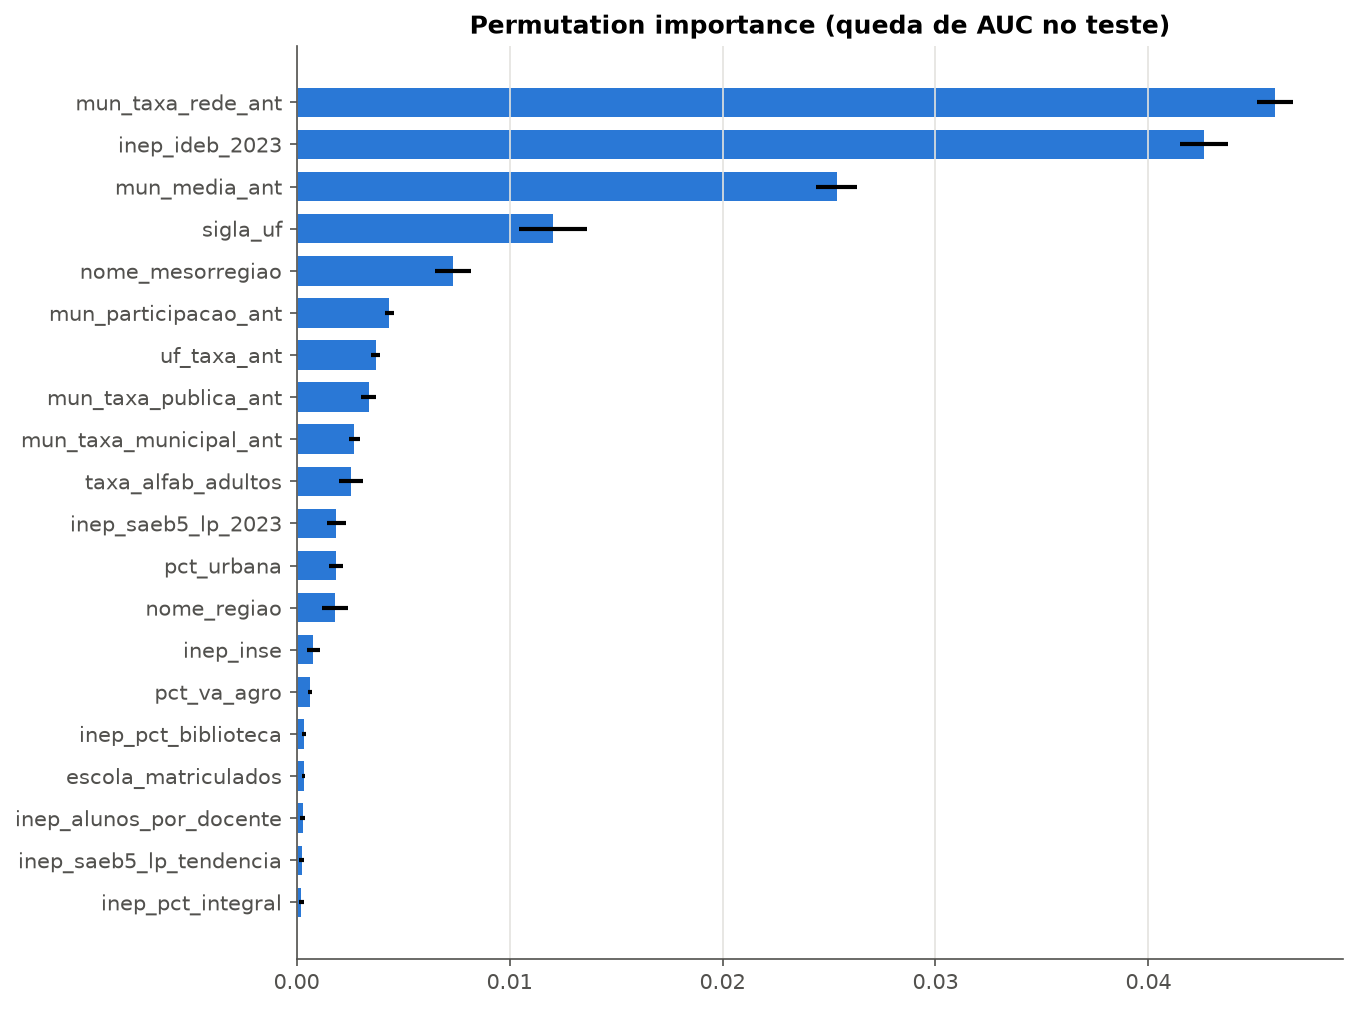

In [3]:
figura("interp_permutation_importance")

## 2. SHAP

In [4]:
shap_medio = pd.read_csv(C.DIR_REPORTS / "importancia_shap.csv", index_col=0)["shap_medio_abs"]
shap_medio.head(15).to_frame()

,shap_medio_abs
mun_taxa_rede_ant,0.2428
inep_ideb_2023,0.2398
mun_media_ant,0.1849
mun_taxa_publica_ant,0.1205
nome_mesorregiao,0.1020
mun_taxa_municipal_ant,0.0931
nome_regiao_Sudeste,0.0849
rede_nome_Estadual,0.0843
sigla_uf_SP,0.0567
taxa_alfab_adultos,0.0564


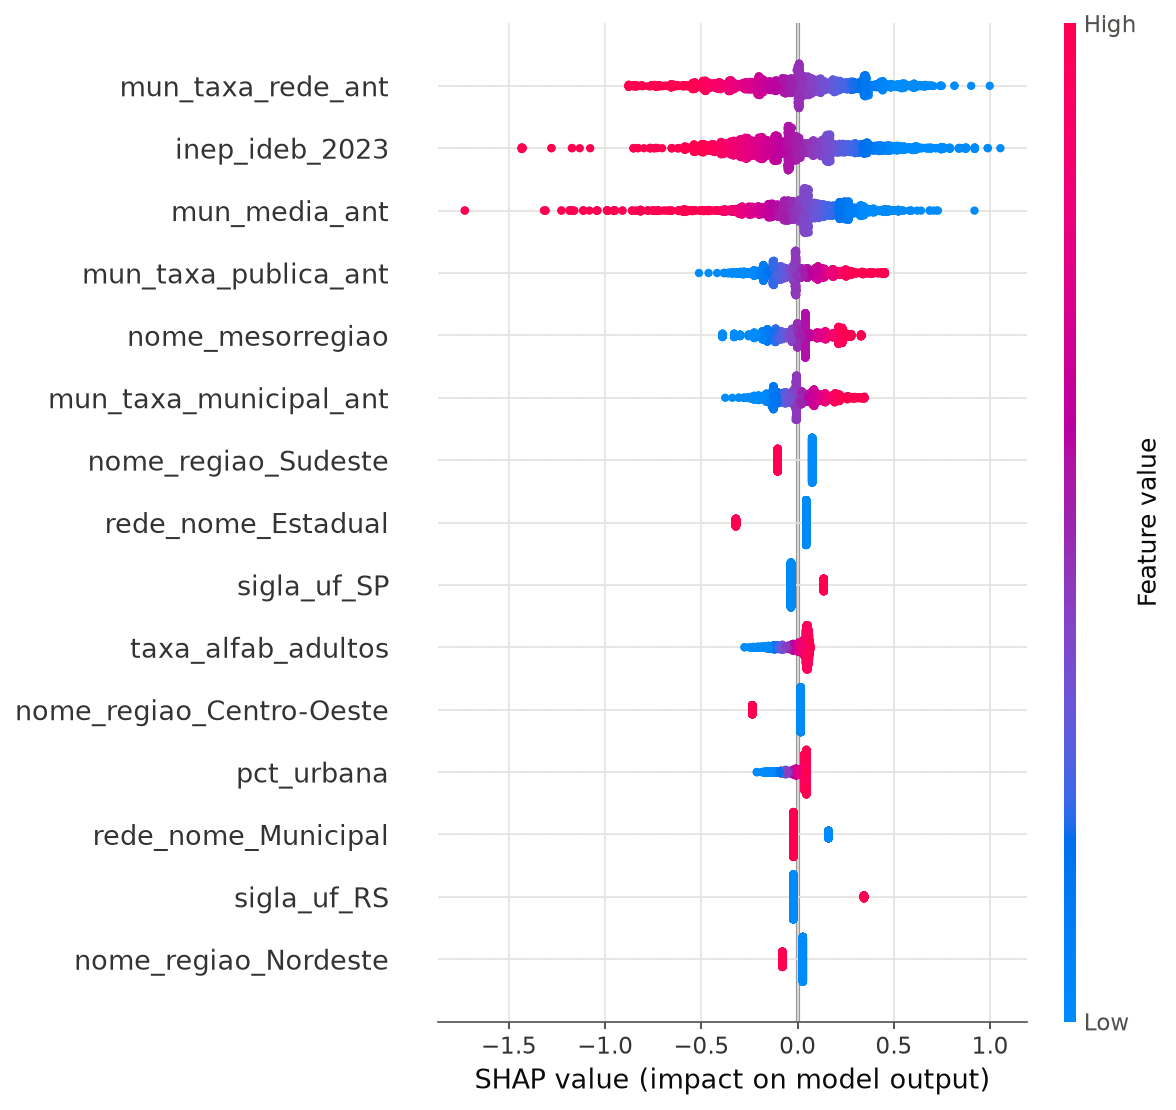

In [5]:
figura("interp_shap_beeswarm")

Cada ponto é um aluno do teste. Quanto mais à direita, mais aquela variável aumentou o
risco de ele não se alfabetizar. A cor mostra o valor da variável: vermelho é alto,
azul é baixo. Por exemplo, municípios com taxa alta no ano anterior (vermelho) ficam à
esquerda, com risco menor.

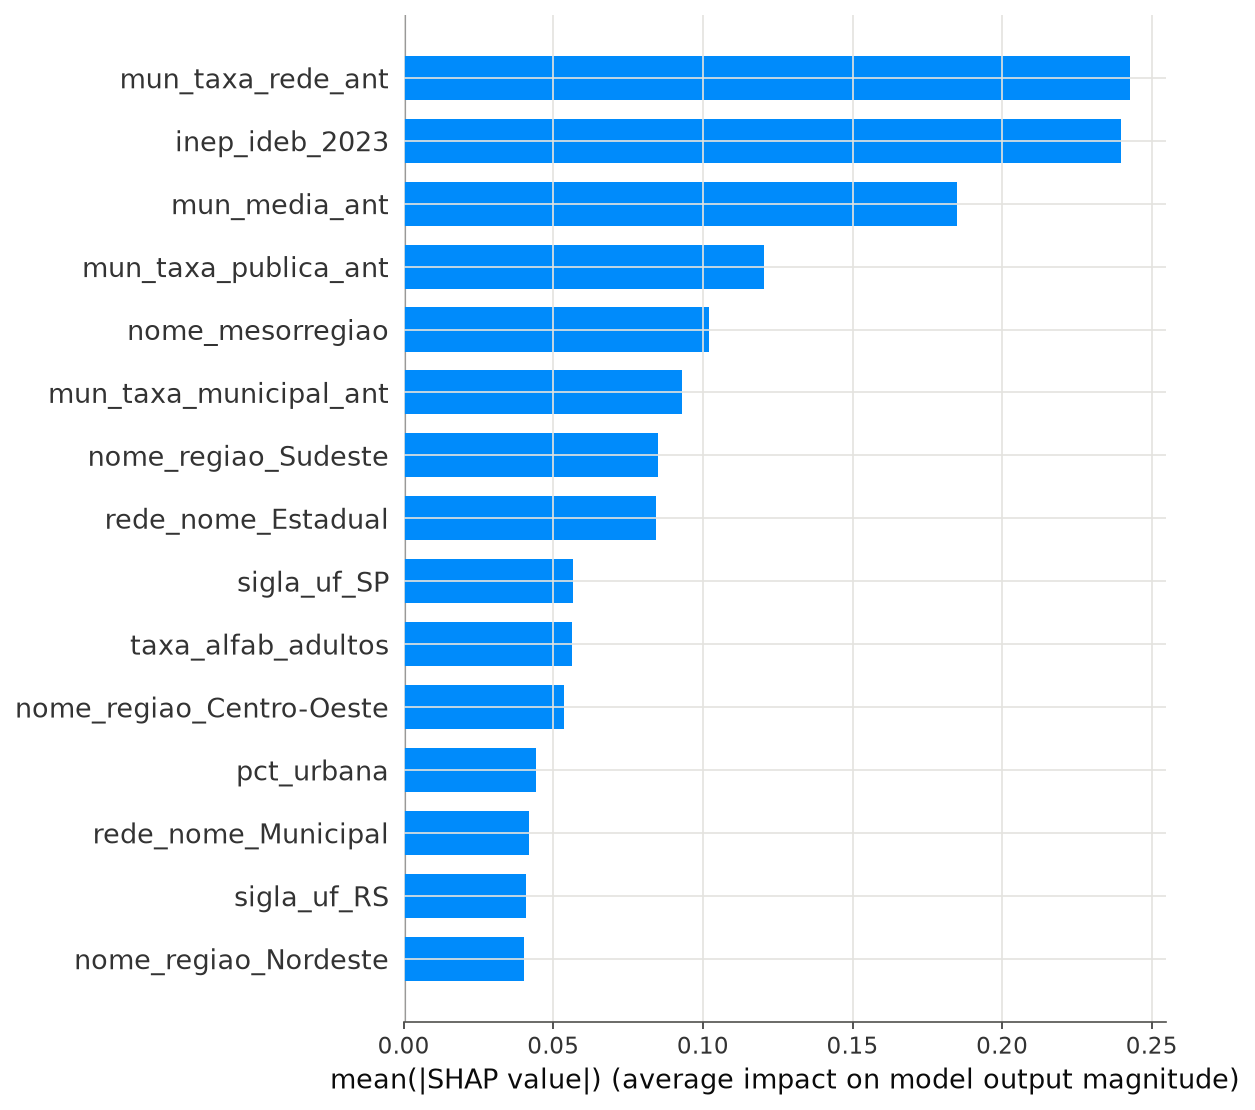

In [6]:
figura("interp_shap_barras", 700)

## 3. Somando por tipo de variável

Para responder "quais fatores mais pesam", juntamos as variáveis em grupos e somamos a
importância de cada grupo.

In [7]:
def bloco(feature):
    f = feature.replace("missingindicator_", "")
    if "escola_matriculados" in f:
        return "Tamanho da escola"
    if f.startswith(("mun_", "uf_")):
        return "Histórico do município / UF"
    if f.startswith(("sigla_uf", "nome_regiao", "nome_mesorregiao")):
        return "Território"
    if f.startswith(("meta", "gap_meta")):
        return "Meta"
    if f.startswith("inep_"):
        return "Escolas da rede (Inep)"
    if f.startswith("rede"):
        return "Rede"
    return "Renda e contexto (IBGE)"

por_bloco = (shap_medio.groupby(shap_medio.index.map(bloco)).sum()
             .sort_values(ascending=False))
(por_bloco / por_bloco.sum()).rename("participação na importância").to_frame().style.format("{:.1%}")

,participação na importância
Histórico do município / UF,36.9%
Território,27.2%
Escolas da rede (Inep),20.9%
Renda e contexto (IBGE),8.4%
Rede,6.1%
Tamanho da escola,0.5%


Pouco mais de um terço da previsão vem do histórico do município, um quarto do
território e um quinto dos dados das escolas do Inep. Renda e tipo de rede ficam com 6%
a 8% cada, e o tamanho da escola quase não pesa.

As duas técnicas apontam as mesmas variáveis no topo: a taxa de alfabetização da rede
no ano anterior e o Ideb 2023 das escolas da mesma rede. Embaralhar qualquer uma delas
derruba a AUC em quase 0,05. Faz sentido, porque as duas medem a qualidade da rede, uma
no 2º ano e outra no 5º.

Respondendo à pergunta do desafio, os fatores que mais impactam a alfabetização são:

1. A qualidade da rede de ensino do município. Como a rede foi no ano anterior é o
   que mais prevê o resultado da criança.
2. O estado e a região. Achamos que eles representam as políticas estaduais de
   alfabetização: Sudeste e Centro-Oeste diminuem o risco, Norte e Nordeste aumentam,
   mas no Nordeste há mesorregiões nos dois extremos.
3. A rede estadual tem risco menor que a municipal, na mesma cidade.
4. Renda e contexto do município pesam pouco depois que entram o histórico e o
   território.

Como o modelo é uma regressão logística, cada variável tem um efeito que vai sempre na
mesma direção. O SHAP mostra o tamanho desse efeito para cada aluno.

## 4. Como o risco muda com as principais variáveis

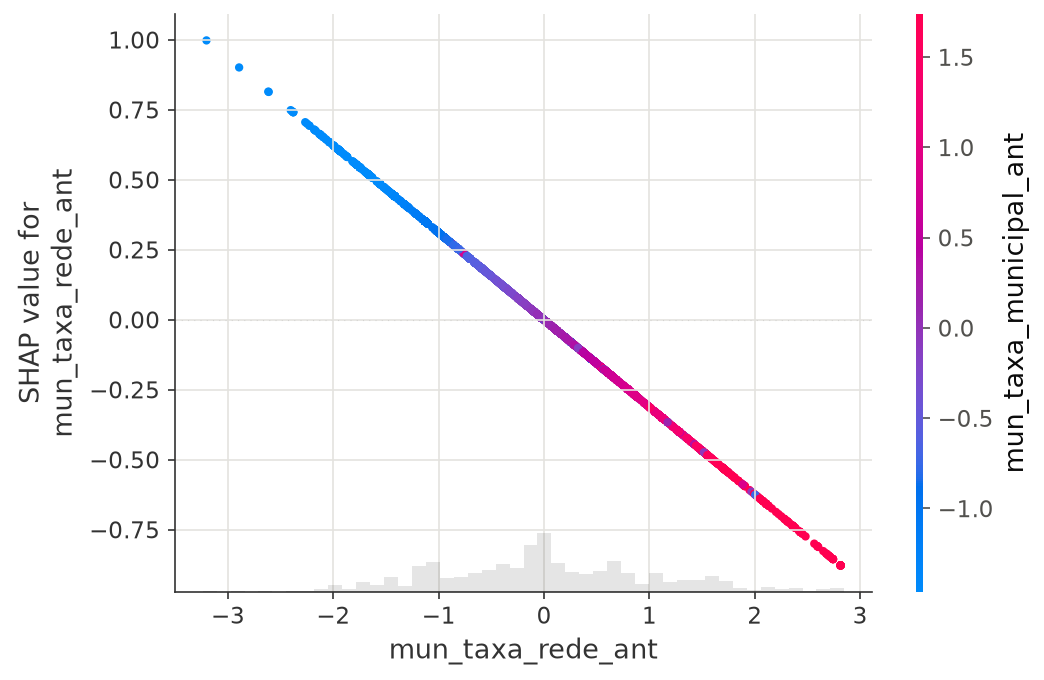

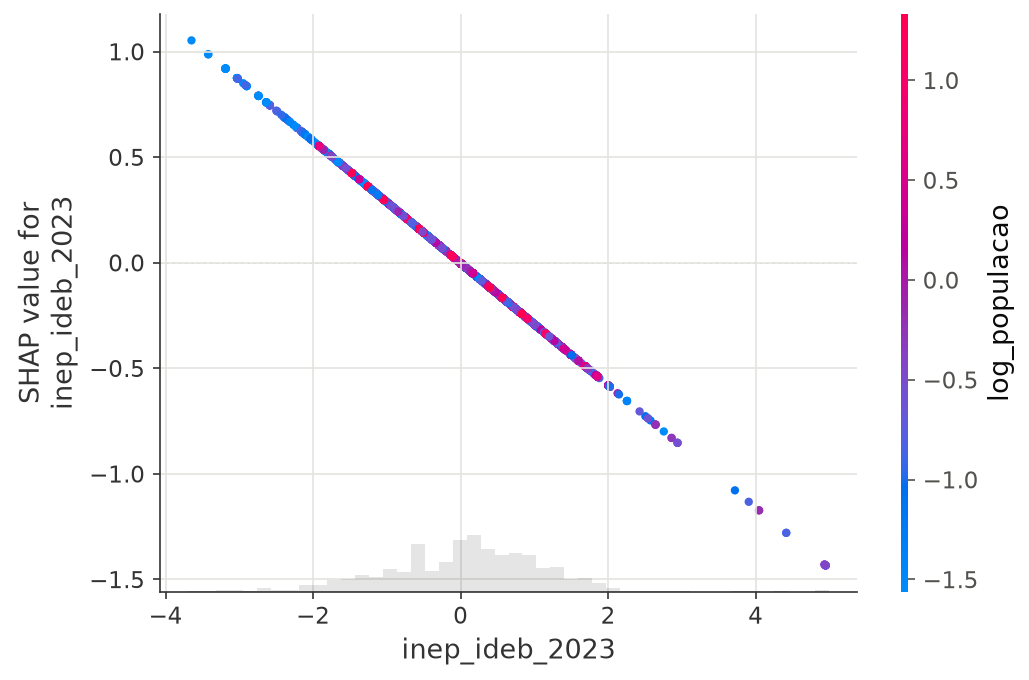

In [8]:
figura("interp_shap_dependencia_1", 650)
figura("interp_shap_dependencia_2", 650)

## 5. Explicando um aluno

Para quem toma decisão, um caso concreto costuma ser mais claro que a média. Abaixo
está o aluno com maior risco previsto na amostra de teste. O gráfico começa no risco
médio e mostra quanto cada variável somou ou tirou até chegar na previsão dele.

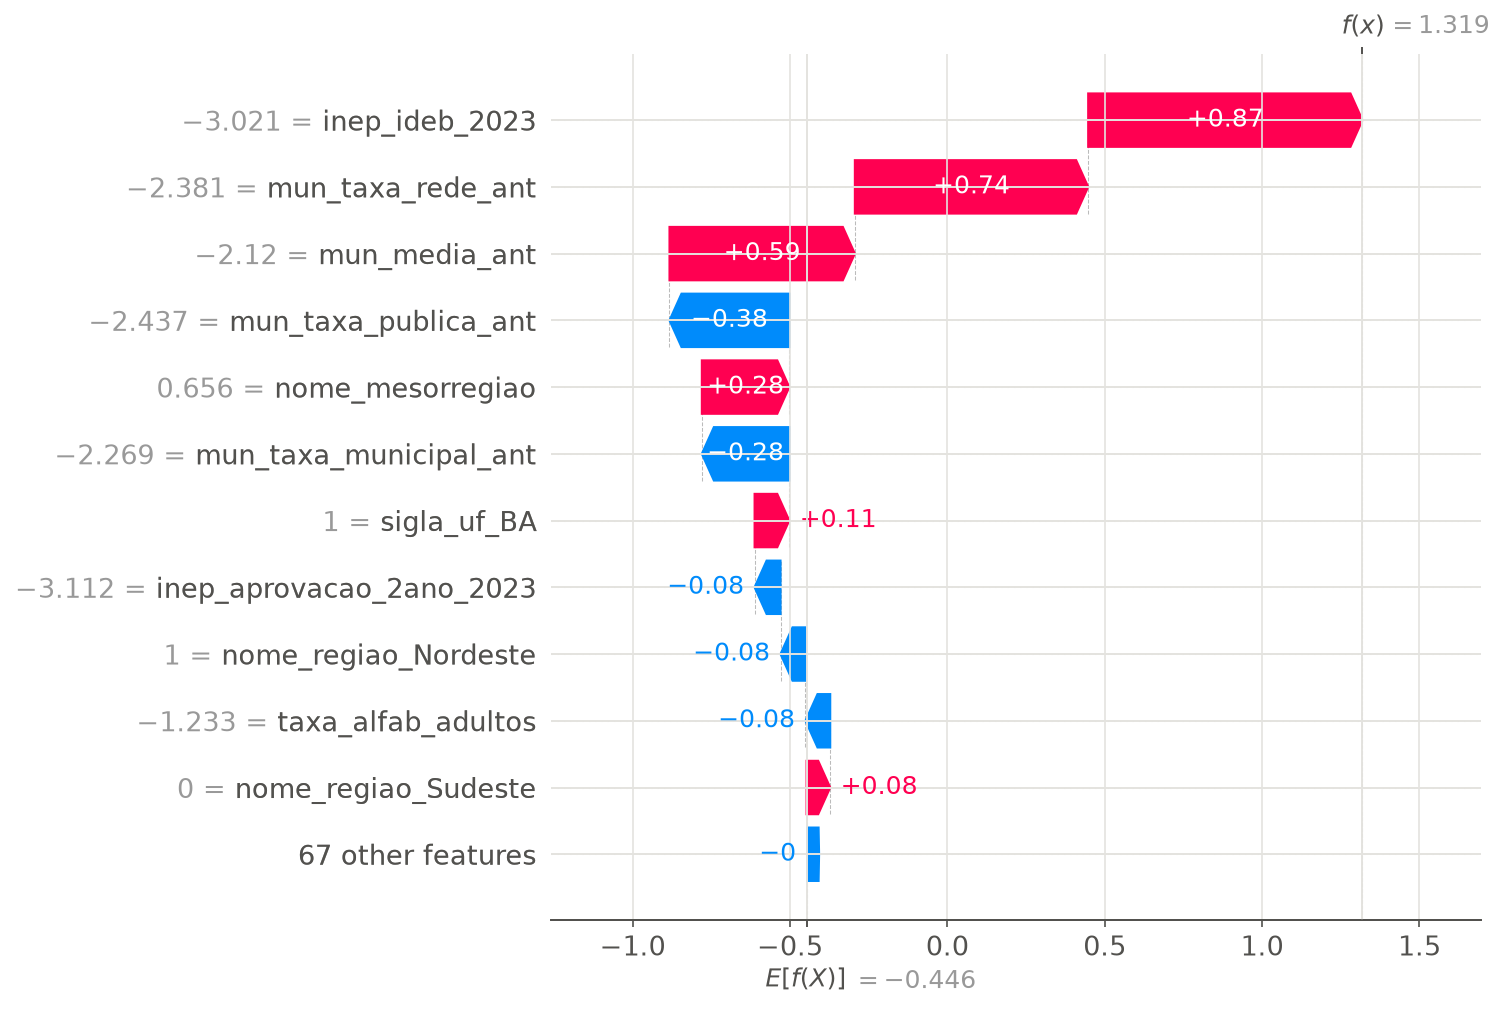

In [9]:
figura("interp_shap_waterfall_aluno_risco", 750)

Os números ao lado de cada variável estão padronizados (quantos desvios-padrão acima ou
abaixo da média), porque é assim que a regressão logística recebe os dados. Esse aluno
está numa rede com taxa e nota bem abaixo da média do país, mais de 2,5 desvios, e
numa mesorregião de risco alto.

Um detalhe: a taxa da rede pública aparece diminuindo o risco, ao contrário da taxa da
rede do aluno. Não é um efeito real. As duas variáveis são quase iguais na maioria das
cidades, e o modelo divide o efeito entre elas com sinais trocados. O que vale olhar é
a soma das duas, que aqui aumenta o risco.

## 6. O modelo trata as regiões de forma diferente?

Comparamos quanto as variáveis de território pesam em cada região. Se a região sozinha
explicasse boa parte do risco, o modelo estaria usando o endereço como atalho, e quem
for usar a previsão precisa saber disso.

In [10]:
alunos = L.carregar_alunos()
base = B.construir_base_aluno(alunos, L.carregar_indicador_municipio(), L.carregar_metas_municipio(),
                              L.carregar_ibge(), L.carregar_censo_escolar(), L.carregar_atlas())
divisao = pd.read_csv(C.DIR_PROCESSADO / "divisao_municipios.csv")
em_teste = base["id_municipio"].isin(divisao.loc[divisao["conjunto"] == "teste", "id_municipio"])
teste, treino_base = base[em_teste], base[~em_teste]
amostra = treino.amostrar(teste, 3_000)
pre, estimador = modelo["preprocessamento"], modelo["modelo"]
X = pre.transform(amostra[cols])
if hasattr(estimador, "get_booster"):
    explicador = shap.TreeExplainer(estimador)
else:
    fundo = pre.transform(treino.amostrar(treino_base, 1_000, semente=1)[cols])
    explicador = shap.LinearExplainer(estimador, shap.maskers.Independent(fundo, max_samples=1000))
valores = explicador(X)
contrib = pd.DataFrame(valores.values, columns=X.columns)
contrib["bloco_territorio"] = contrib[[c for c in X.columns if bloco(c) == "Território"]].sum(axis=1)
contrib["bloco_historico"] = contrib[[c for c in X.columns if bloco(c).startswith("Histórico")]].sum(axis=1)
contrib["bloco_renda"] = contrib[[c for c in X.columns if bloco(c).startswith("Renda")]].sum(axis=1)
contrib["regiao"] = amostra["nome_regiao"].astype(str).to_numpy()
contrib.groupby("regiao")[["bloco_historico", "bloco_territorio", "bloco_renda"]].mean()

,bloco_historico,bloco_territorio,bloco_renda
regiao,,,
Centro-Oeste,-0.0697,-0.2657,0.0189
Nordeste,0.0340,0.0830,-0.0683
Norte,0.1714,0.0640,-0.0404
Sudeste,0.0097,-0.0168,0.0266
Sul,-0.1396,0.2168,0.0260


Valores positivos aumentam o risco previsto e negativos diminuem.

O território aumenta o risco no Sul (por causa da queda do RS em 2024), no Nordeste e
no Norte, e diminui no Centro-Oeste e no Sudeste. O peso dele é parecido com o do
histórico. É esperado, já que a diferença entre regiões existe nos dados, mas isso tem
duas consequências práticas:

- duas escolas com o mesmo histórico recebem riscos diferentes dependendo da região.
  Para decidir onde colocar apoio, tudo bem, porque mostra onde o problema está. Para
  avaliar uma escola ou um gestor, não seria justo, porque penalizaria pelo endereço;
- um município do Norte ou do Nordeste com bom histórico pode ficar com uma previsão
  mais pessimista do que merece, e vale olhar caso a caso.

A renda pesa menos que o território em todas as regiões, e no Nordeste ela até diminui
o risco. Ou seja, o modelo não está usando pobreza como atalho.